In [ ]:
# Data Manipulation
import pandas as pd
import numpy as np
import cudf

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Preprocessing & Metrics
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from datetime import datetime

# Machine Learning (GPU-accelerated)
import cuml
from cuml.cluster import KMeans

# Machine Learning (CPU/Standard - for GMM)
from sklearn.mixture import GaussianMixture

# 1. LOAD DATA
users = pd.read_csv('users.csv', delimiter=";")
orders = pd.read_csv('orders.csv')
order_items = pd.read_csv('order_items.csv')
events = pd.read_csv('events.csv')

# Chuyển đổi định dạng thời gian
for df in [orders, events]:
    df['created_at'] = pd.to_datetime(df['created_at'],format='mixed')



/tmp/ipykernel_3379/2663614980.py:8: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  users = pd.read_csv('users.csv', delimiter=";")


In [ ]:
# 2. FEATURE ENGINEERING (HÀNH VI WEB - V, D, A)
# Tính Duration cho mỗi session: Max - Min thời gian trong 1 session
session_stats = events.groupby(['user_id', 'session_id']).agg(
    start_time=('created_at', 'min'),
    end_time=('created_at', 'max'),
    action_count=('id', 'count')
)
session_stats['duration_sec'] = (session_stats['end_time'] - session_stats['start_time']).dt.total_seconds()

# Tổng hợp theo User (Visits, Durations, Actions)
web_behavior = session_stats.groupby('user_id').agg(
    Visits=('duration_sec', 'count'),
    Durations=('duration_sec', 'sum'),
    Actions=('action_count', 'sum')
).reset_index()

# 3. FEATURE ENGINEERING (GIAO DỊCH - R, F, M ++)
# Tính Recency, Frequency, Monetary
now = orders['created_at'].max()
order_items_gb = order_items.groupby('order_id').agg(
    sale_price=('sale_price', 'sum'))

order_summary = orders.merge(order_items_gb, on='order_id')


rfm_base = order_summary.groupby('user_id').agg(
    Last_Purchase=('created_at', 'max'),
    Frequency=('order_id', 'nunique'),
    Monetary=('sale_price', 'sum')
).reset_index()

rfm_base['Recency'] = (now - rfm_base['Last_Purchase']).dt.days
rfm_base

,user_id,Last_Purchase,Frequency,Monetary,Recency
0,1,2025-08-20 12:35:00,1,25.000000,27
1,2,2020-07-23 03:04:00,1,7.500000,1881
2,3,2025-05-15 10:04:00,3,234.939997,124
3,5,2025-08-23 00:29:00,2,283.019997,24
4,6,2025-08-10 17:52:00,2,55.000000,37
...,...,...,...,...,...
80068,99996,2024-12-23 16:14:00,3,161.480000,267
80069,99997,2024-08-18 07:15:00,1,64.949997,394
80070,99998,2024-10-29 17:49:00,2,118.380003,322
80071,99999,2023-04-07 08:59:00,1,14.900000,893


In [ ]:
# 1. TÍNH DIVERSITY (D)
product_view = events[events['event_type']=='product'].groupby('user_id')['uri'].nunique().reset_index(name='Diversity_View')
# 2. TÍNH ADD TO CART COUNT - TỪ BẢNG events
cart_actions = events[events['event_type'] == 'cart'].groupby('user_id').size().reset_index(name='Add_to_Cart_Count')


# 4. GỘP TẤT CẢ VÀO MASTER DATASET
# Chia làm 2 nhóm: Purchasing (RFMVDA++) và Non-Purchasing (VDAR)
master_df = web_behavior.merge(rfm_base, on='user_id', how='left')
# master_df = master_df.merge(diversity_df, on='user_id', how='left')
master_df = master_df.merge(cart_actions, on='user_id', how='left')
master_df = master_df.merge(product_view, on='user_id', how='left')

# Xử lý giá trị trống cho người chưa mua hàng
master_df[['Recency', 'Frequency', 'Monetary','Diversity_View','Add_to_Cart_Count']] = master_df[['Recency', 'Frequency', 'Monetary','Diversity_View','Add_to_Cart_Count']].fillna(0)

purchasing_users = master_df[master_df['Frequency'] > 0].copy()


In [ ]:
# 1. Định nghĩa danh sách các đặc trưng RFMVDA++
rfmvda_cols = ['Recency', 'Frequency', 'Monetary', 'Visits', 'Durations', 'Actions','Diversity_View','Add_to_Cart_Count']
purchasing_users[rfmvda_cols].info()
purchasing_users[rfmvda_cols].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80073 entries, 0 to 80072
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Recency            80073 non-null  int64  
 1   Frequency          80073 non-null  int64  
 2   Monetary           80073 non-null  float64
 3   Visits             80073 non-null  int64  
 4   Durations          80073 non-null  float64
 5   Actions            80073 non-null  int64  
 6   Diversity_View     80073 non-null  int64  
 7   Add_to_Cart_Count  80073 non-null  int64  
dtypes: float64(2), int64(6)
memory usage: 4.9 MB


,Recency,Frequency,Monetary,Visits,Durations,Actions,Diversity_View,Add_to_Cart_Count
count,80073.000000,80073.000000,80073.000000,80073.000000,8.007300e+04,80073.000000,80073.000000,80073.000000
mean,508.159392,1.560988,134.846679,2.270178,2.043996e+05,16.327239,2.269929,4.322381
std,501.932203,0.861256,138.340401,1.611126,3.162845e+05,16.885187,1.610764,5.154463
min,0.000000,1.000000,0.490000,1.000000,3.000000e+01,5.000000,1.000000,1.000000
25%,109.000000,1.000000,41.289999,1.000000,3.760000e+02,5.000000,1.000000,1.000000
50%,339.000000,1.000000,89.599998,2.000000,7.210000e+02,10.000000,2.000000,2.000000
75%,770.000000,2.000000,181.120007,3.000000,3.480860e+05,19.000000,3.000000,5.000000
max,2422.000000,4.000000,1950.510006,14.000000,3.124950e+06,170.000000,14.000000,52.000000


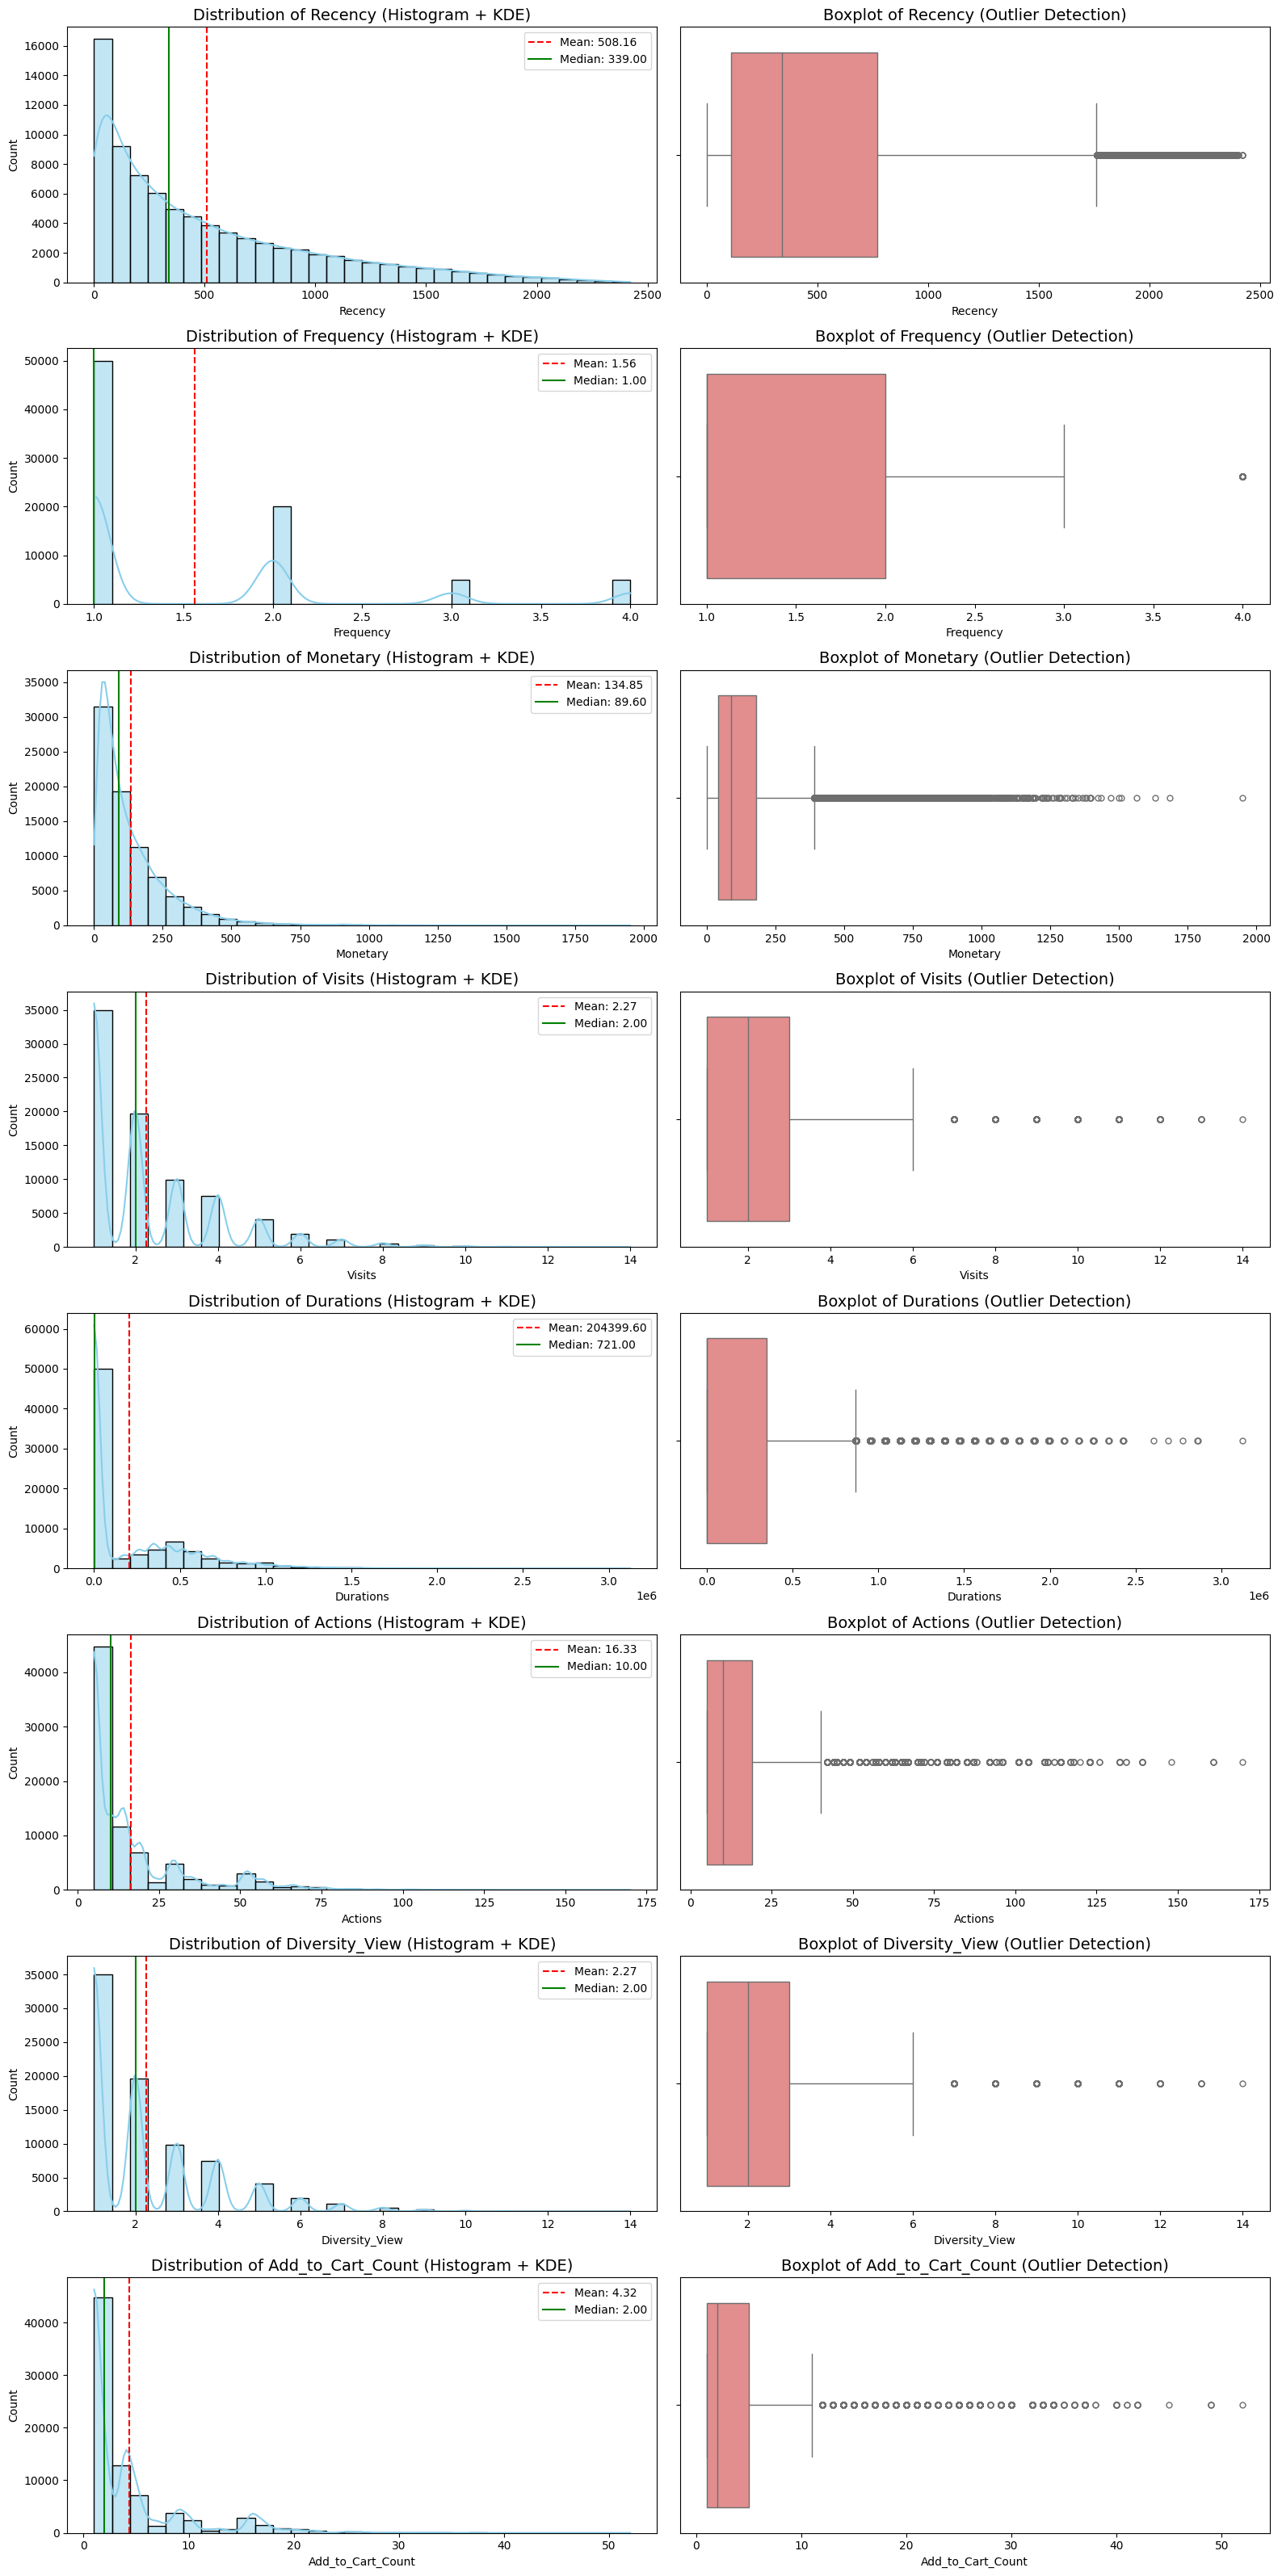

In [ ]:

# 2. Cấu hình vùng vẽ biểu đồ
fig, axes = plt.subplots(nrows=len(rfmvda_cols), ncols=2, figsize=(16, 4 * len(rfmvda_cols)))

for i, col in enumerate(rfmvda_cols):
    # --- Vẽ Histogram + KDE ---
    sns.histplot(purchasing_users[col], kde=True, ax=axes[i, 0], color='skyblue', bins=30)

    mean_val = purchasing_users[col].mean()
    median_val = purchasing_users[col].median()

    axes[i, 0].axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:.2f}')
    axes[i, 0].axvline(median_val, color='green', linestyle='-', label=f'Median: {median_val:.2f}')

    axes[i, 0].set_title(f'Distribution of {col} (Histogram + KDE)', fontsize=14)
    axes[i, 0].legend()

    # --- Vẽ Boxplot ---
    sns.boxplot(x=purchasing_users[col], ax=axes[i, 1], color='lightcoral', fliersize=5)
    axes[i, 1].set_title(f'Boxplot of {col} (Outlier Detection)', fontsize=14)

# 3. Xử lý Log-scale cho các biến bị lệch phải nặng (như Monetary, Actions)

plt.tight_layout()
plt.savefig('rfmvda_distribution_analysis.png')
plt.show()

In [ ]:


# 1. Danh sách các biến cần Log-transform trước khi scale
cols_to_log = ['Recency', 'Monetary', 'Durations', 'Actions','Add_to_Cart_Count']
cols_to_scale_only = ['Frequency', 'Visits','Diversity_View']

# # # Áp dụng Log(x+1) để xử lý đuôi dài
# for col in cols_to_log:
#     purchasing_users[col] = np.log1p(purchasing_users[col])

# 2. Thực hiện Min-Max Scaling đưa về thang 0-5 (Theo paper RFMVDA)
scaler = MinMaxScaler(feature_range=(0, 5))
all_features = cols_to_log + cols_to_scale_only

purchasing_users_scaled = purchasing_users.copy()
purchasing_users_scaled[all_features] = scaler.fit_transform(purchasing_users[all_features])

# Kiểm tra kết quả
print(purchasing_users_scaled[all_features].describe())

            Recency      Monetary     Durations       Actions  \
count  80073.000000  80073.000000  80073.000000  80073.000000   
mean       1.049049      0.344501      0.327000      0.343250   
std        1.036194      0.354715      0.506068      0.511672   
min        0.000000      0.000000      0.000000      0.000000   
25%        0.225021      0.104614      0.000554      0.000000   
50%        0.699835      0.228485      0.001106      0.151515   
75%        1.589595      0.463149      0.556904      0.424242   
max        5.000000      5.000000      5.000000      5.000000   

       Add_to_Cart_Count     Frequency        Visits  Diversity_View  
count       80073.000000  80073.000000  80073.000000    80073.000000  
mean            0.325724      0.934980      0.488530        0.488434  
std             0.505340      1.435427      0.619664        0.619525  
min             0.000000      0.000000      0.000000        0.000000  
25%             0.000000      0.000000      0.000000       

🚀 Đang phân tích trên 80073 dòng (Silhouette tính trên mẫu 20000 dòng)...
✅ K=2 | Silhouette: 0.5090
✅ K=3 | Silhouette: 0.3772
✅ K=4 | Silhouette: 0.3870
✅ K=5 | Silhouette: 0.4467
✅ K=6 | Silhouette: 0.4462
✅ K=7 | Silhouette: 0.4531
✅ K=8 | Silhouette: 0.4540
✅ K=9 | Silhouette: 0.4530
✅ K=10 | Silhouette: 0.4628


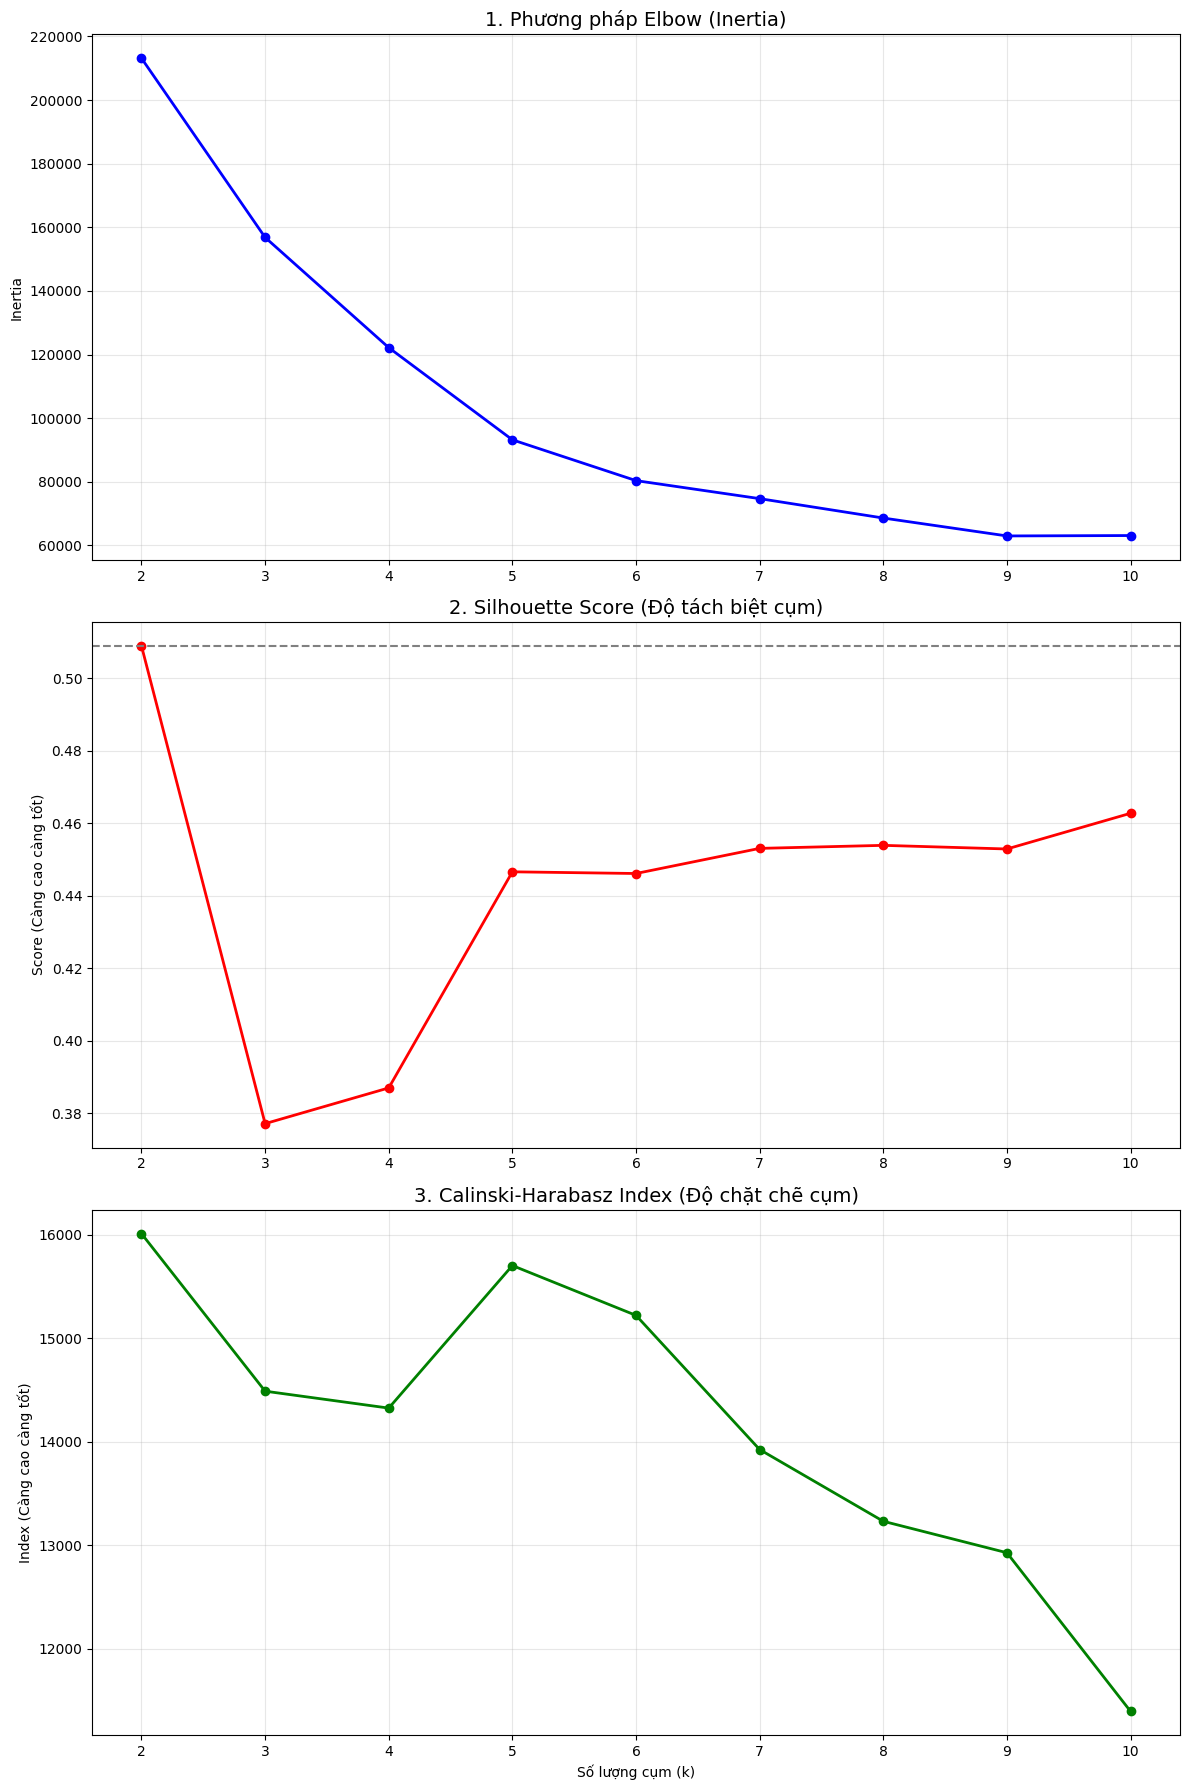

In [ ]:


def evaluate_clusters_comprehensive(df, features, max_k=10, sample_size=20000):
    # 1. Chuẩn bị dữ liệu GPU và mẫu CPU
    gdf = cudf.from_pandas(df[features])
    # Lấy mẫu để tính Silhouette
    df_sample = df[features].sample(n=sample_size, random_state=42)

    inertia = []
    ch_scores = []
    silhouette_avg = []
    k_range = range(2, max_k + 1)

    print(f"🚀 Đang phân tích trên {len(df)} dòng (Silhouette tính trên mẫu {sample_size} dòng)...")

    for k in k_range:
        # Chạy KMeans trên GPU (Tất cả 80k dòng)
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(gdf)

        # Lưu Inertia
        inertia.append(kmeans.inertia_)

        # Dự đoán nhãn cho mẫu để tính Score
        labels_all = kmeans.predict(gdf).to_numpy()
        df['temp_label'] = labels_all
        labels_sample = df.loc[df_sample.index, 'temp_label'].values

        # Tính CH Index (Toàn bộ hoặc mẫu)
        ch_scores.append(calinski_harabasz_score(df_sample, labels_sample))

        # Tính Silhouette Score (Trên mẫu)
        sil_score = silhouette_score(df_sample, labels_sample)
        silhouette_avg.append(sil_score)

        print(f"✅ K={k} | Silhouette: {sil_score:.4f}")

    # --- VẼ BIỂU ĐỒ 3 TRONG 1 ---
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 18))

    # 1. Elbow Method
    ax1.plot(k_range, inertia, 'bo-', linewidth=2)
    ax1.set_title('1. Phương pháp Elbow (Inertia)', fontsize=14)
    ax1.set_ylabel('Inertia')
    ax1.grid(True, alpha=0.3)

    # 2. Silhouette Score
    ax2.plot(k_range, silhouette_avg, 'ro-', linewidth=2)
    ax2.set_title('2. Silhouette Score (Độ tách biệt cụm)', fontsize=14)
    ax2.set_ylabel('Score (Càng cao càng tốt)')
    ax2.axhline(y=max(silhouette_avg), color='gray', linestyle='--')
    ax2.grid(True, alpha=0.3)

    # 3. Calinski-Harabasz Index
    ax3.plot(k_range, ch_scores, 'go-', linewidth=2)
    ax3.set_title('3. Calinski-Harabasz Index (Độ chặt chẽ cụm)', fontsize=14)
    ax3.set_ylabel('Index (Càng cao càng tốt)')
    ax3.set_xlabel('Số lượng cụm (k)')
    ax3.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('comprehensive_cluster_evaluation.png')
    plt.show()

# Thực thi
rfmvda_features = ['Recency', 'Frequency', 'Monetary', 'Visits', 'Durations', 'Actions','Diversity_View','Add_to_Cart_Count']

evaluate_clusters_comprehensive(purchasing_users_scaled, rfmvda_features)

🚀 Đang chạy GMM (sklearn) trên 80073 dòng...
⚠️ Silhouette & CH Index sẽ được tính trên mẫu 10000 dòng để đảm bảo tốc độ.
✅ K=2 | BIC: -2054328.97 | Silhouette: 0.3612
✅ K=3 | BIC: -3295207.75 | Silhouette: 0.2558
✅ K=4 | BIC: -2697105.08 | Silhouette: 0.3306
✅ K=5 | BIC: -2821785.41 | Silhouette: 0.3455
✅ K=6 | BIC: -3054236.00 | Silhouette: 0.3201
✅ K=7 | BIC: -4009403.02 | Silhouette: 0.2820
✅ K=8 | BIC: -4016769.87 | Silhouette: 0.2805
✅ K=9 | BIC: -4021299.92 | Silhouette: 0.2024
✅ K=10 | BIC: -4290115.28 | Silhouette: 0.2689


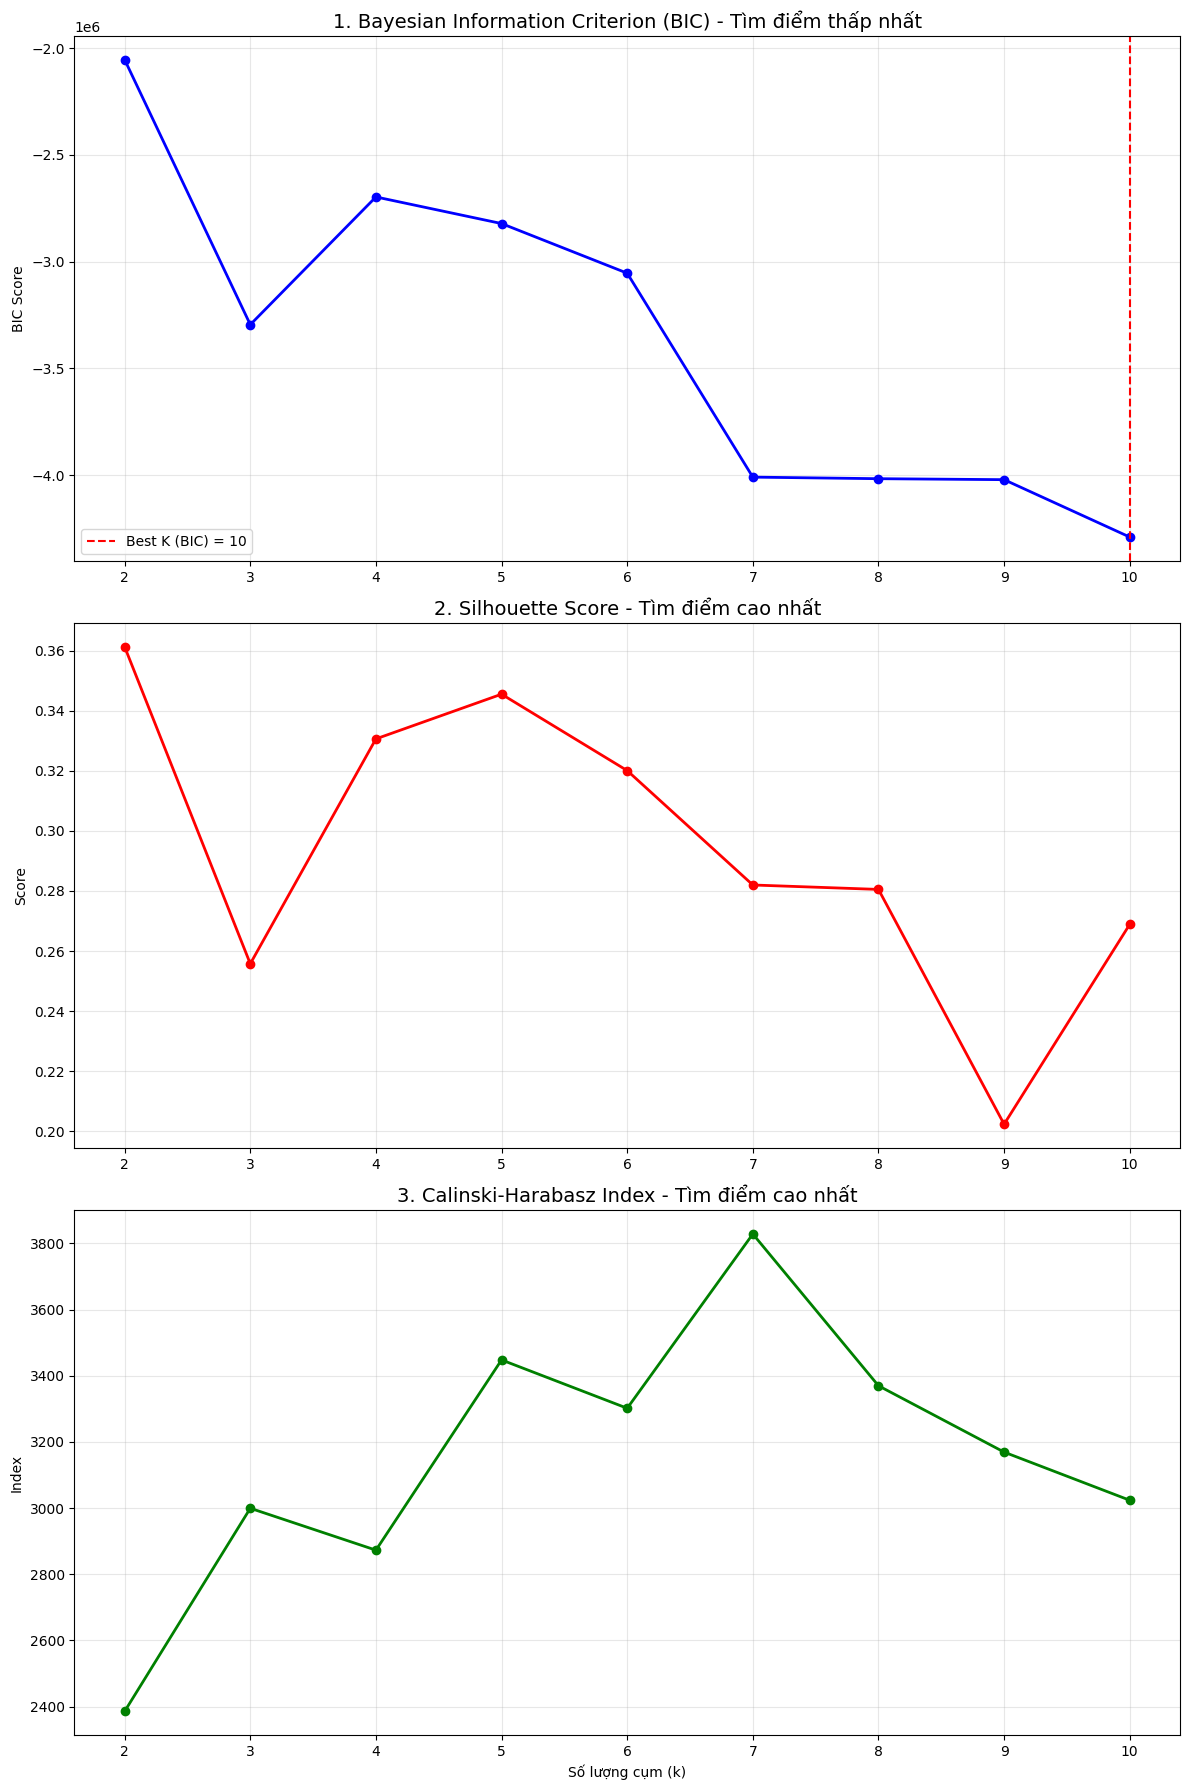

In [ ]:


def evaluate_gmm_sklearn(df, features, max_k=10, sample_size=10000):
    # 1. Chuẩn bị dữ liệu (Dùng NumPy array cho sklearn)
    X = df[features].values

    # Lấy mẫu để tính toán các chỉ số nặng như Silhouette (tránh treo máy trên CPU)
    df_sample = df[features].sample(n=sample_size, random_state=42)
    X_sample = df_sample.values

    bic_scores = []
    ch_scores = []
    silhouette_avg = []
    k_range = range(2, max_k + 1)

    print(f"🚀 Đang chạy GMM (sklearn) trên {len(df)} dòng...")
    print(f"⚠️ Silhouette & CH Index sẽ được tính trên mẫu {sample_size} dòng để đảm bảo tốc độ.")

    for k in k_range:
        # Khởi tạo GMM
        # covariance_type='full' cho phép cụm có hình dạng elip linh hoạt
        gmm = GaussianMixture(n_components=k, covariance_type='full', random_state=42)
        gmm.fit(X)

        # 1. Tính BIC (Bayesian Information Criterion) - Chỉ số quan trọng nhất của GMM
        # BIC càng thấp mô hình càng tối ưu (cân bằng giữa độ khớp và độ phức tạp)
        bic_scores.append(gmm.bic(X))

        # Dự đoán nhãn cho mẫu
        labels_sample = gmm.predict(X_sample)

        # 2. Tính CH Index (Độ chặt chẽ và tách biệt - Càng cao càng tốt)
        ch_scores.append(calinski_harabasz_score(X_sample, labels_sample))

        # 3. Tính Silhouette Score (Độ khớp của điểm với cụm - Càng cao càng tốt)
        sil_score = silhouette_score(X_sample, labels_sample)
        silhouette_avg.append(sil_score)

        print(f"✅ K={k} | BIC: {bic_scores[-1]:.2f} | Silhouette: {sil_score:.4f}")

    # --- VẼ BIỂU ĐỒ SO SÁNH ---
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 18))

    # Đồ thị BIC
    ax1.plot(k_range, bic_scores, 'bo-', linewidth=2)
    ax1.set_title('1. Bayesian Information Criterion (BIC) - Tìm điểm thấp nhất', fontsize=14)
    ax1.set_ylabel('BIC Score')
    ax1.grid(True, alpha=0.3)
    best_k_bic = k_range[np.argmin(bic_scores)]
    ax1.axvline(x=best_k_bic, color='red', linestyle='--', label=f'Best K (BIC) = {best_k_bic}')
    ax1.legend()

    # Đồ thị Silhouette
    ax2.plot(k_range, silhouette_avg, 'ro-', linewidth=2)
    ax2.set_title('2. Silhouette Score - Tìm điểm cao nhất', fontsize=14)
    ax2.set_ylabel('Score')
    ax2.grid(True, alpha=0.3)

    # Đồ thị Calinski-Harabasz
    ax3.plot(k_range, ch_scores, 'go-', linewidth=2)
    ax3.set_title('3. Calinski-Harabasz Index - Tìm điểm cao nhất', fontsize=14)
    ax3.set_ylabel('Index')
    ax3.set_xlabel('Số lượng cụm (k)')
    ax3.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Danh sách tính năng kết hợp từ RFM-D, RFMCV và RFMVDA
rfmvda_cp_features = [
    'Recency', 'Frequency', 'Monetary',
    'Visits', 'Durations', 'Actions',
    'Diversity_View',
    'Add_to_Cart_Count'
]

# Thực thi (Lưu ý: purchasing_users_scaled phải là DataFrame đã chuẩn hóa)
evaluate_gmm_sklearn(purchasing_users_scaled, rfmvda_cp_features)

In [ ]:
# 1. Chuyển dữ liệu sang GPU
gdf = cudf.from_pandas(purchasing_users_scaled[rfmvda_features])

# 2. Huấn luyện KMeans với k=5 (Dựa trên đỉnh CH Index và khuỷu tay Elbow)
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(gdf)

# 3. Lấy nhãn dự đoán và đưa về CPU (NumPy) để tính toán metrics
labels_all = kmeans.labels_.to_numpy()
purchasing_users_scaled['Cluster'] = labels_all

# 4. CH Index: Tính trên toàn bộ 80k dòng # Dùng dữ liệu gốc dạng Pandas/Numpy
data_cpu = purchasing_users_scaled[rfmvda_features].values
ch_index = calinski_harabasz_score(data_cpu, labels_all)
print(f"✅ Calinski-Harabasz Index (toàn bộ 80k dòng): {ch_index:.2f}")

# 5. Silhouette Score: Bắt buộc lấy mẫu để tránh Crash RAM [cite: 559]
sample_size = len(gdf)
sample_indices = np.random.choice(len(data_cpu), sample_size, replace=False)

data_sample = data_cpu[sample_indices]
labels_sample = labels_all[sample_indices]

sil_score = silhouette_score(data_sample, labels_sample)
print(f"✅ Silhouette Score (mẫu {sample_size} dòng): {sil_score:.4f}")

✅ Calinski-Harabasz Index (toàn bộ 80k dòng): 62556.36
✅ Silhouette Score (mẫu 80073 dòng): 0.4449


/tmp/ipykernel_3379/1939058934.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=label_col, y=col, data=df, palette='viridis', showfliers=True)
/tmp/ipykernel_3379/1939058934.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=label_col, y=col, data=df, palette='viridis', showfliers=True)
/tmp/ipykernel_3379/1939058934.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=label_col, y=col, data=df, palette='viridis', showfliers=True)
/tmp/ipykernel_3379/1939058934.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is 

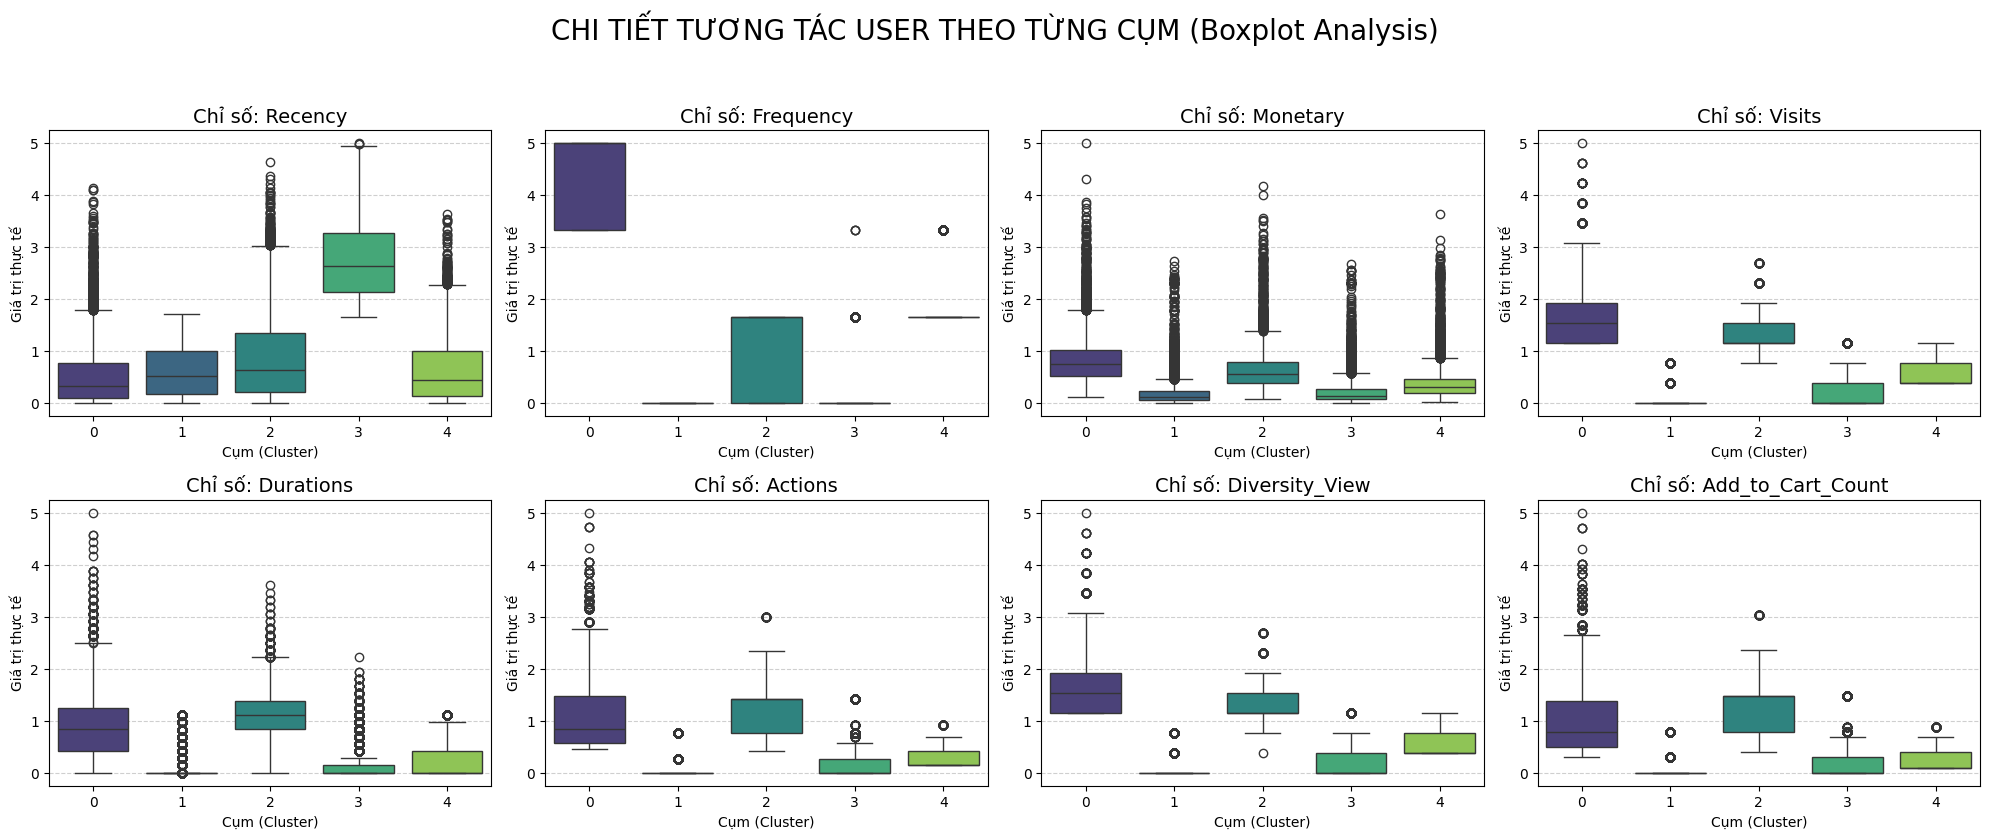

👥 Số lượng User trong mỗi cụm:
- Cluster 0: 8213 users (Chiếm 10.26%)
- Cluster 1: 32159 users (Chiếm 40.16%)
- Cluster 2: 8476 users (Chiếm 10.59%)
- Cluster 3: 14973 users (Chiếm 18.70%)
- Cluster 4: 16252 users (Chiếm 20.30%)


In [ ]:
def visualize_cluster_details(df, features, label_col='Cluster'):
    # 1. Thống kê số lượng user mỗi cụm
    cluster_counts = df[label_col].value_counts().sort_index()

    plt.figure(figsize=(20, 15))
    plt.suptitle('CHI TIẾT TƯƠNG TÁC USER THEO TỪNG CỤM (Boxplot Analysis)', fontsize=20, y=1.02)

    for i, col in enumerate(features):
        plt.subplot(4, 4, i+1)
        # Vẽ Boxplot để xem dải tương tác thực tế của user trong cụm
        sns.boxplot(x=label_col, y=col, data=df, palette='viridis', showfliers=True)

        # Thêm tên cụm và số lượng user tương ứng vào nhãn X
        plt.title(f'Chỉ số: {col}', fontsize=14)
        plt.xlabel('Cụm (Cluster)')
        plt.ylabel('Giá trị thực tế')
        plt.grid(axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

    # In ra bảng số lượng user cụ thể từng cụm
    print("👥 Số lượng User trong mỗi cụm:")
    for cluster, count in cluster_counts.items():
        print(f"- Cluster {cluster}: {count} users (Chiếm {count/len(df)*100:.2f}%)")

# Thực thi sau khi đã gán nhãn Cluster vào DataFrame gốc (purchasing_users)
visualize_cluster_details(purchasing_users_scaled, rfmvda_cp_features)

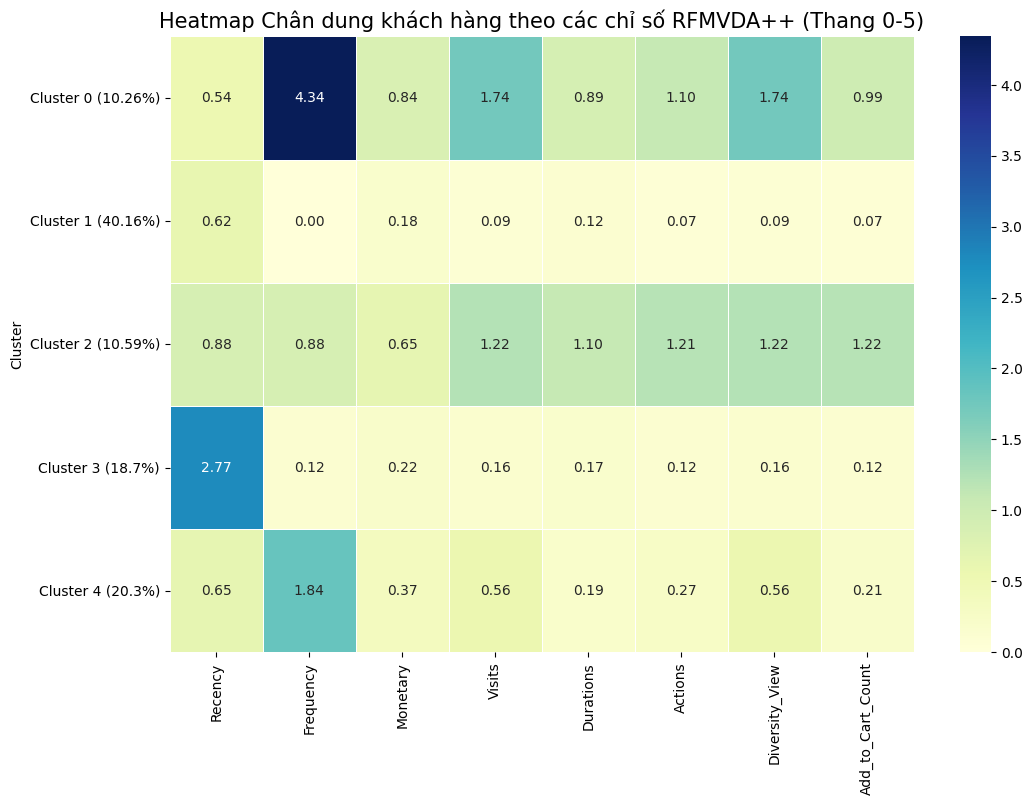

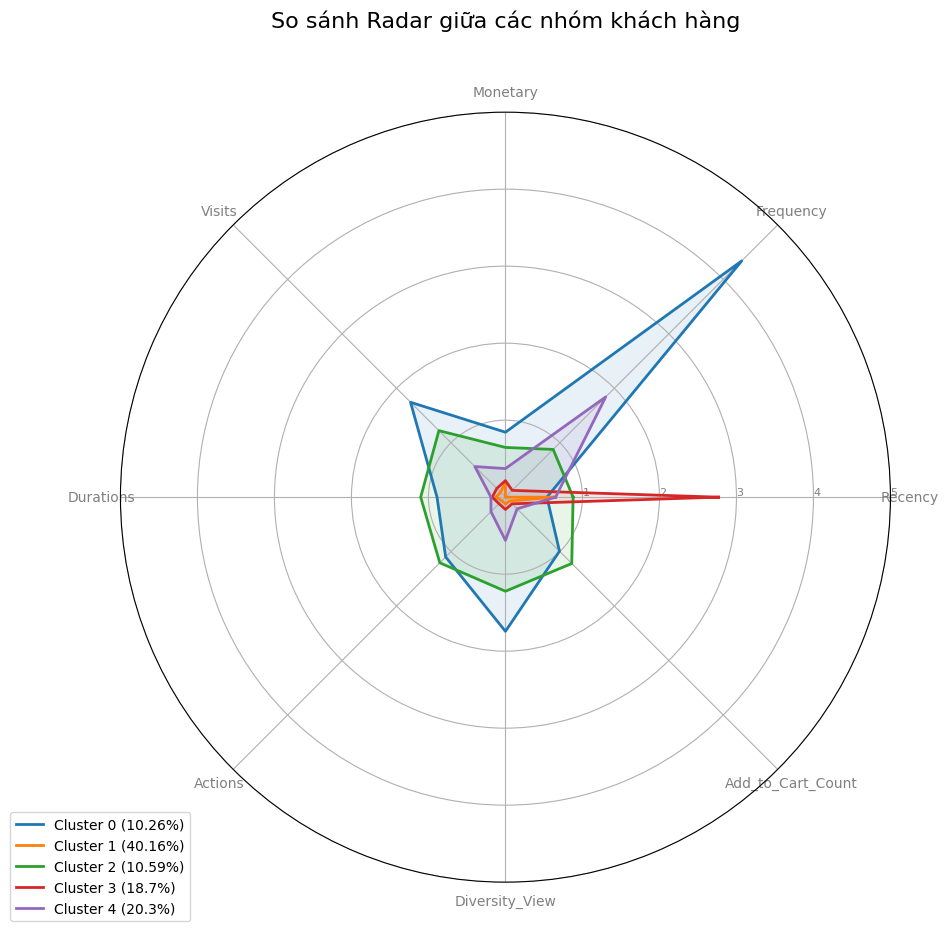

In [ ]:
# 1. Tính toán giá trị trung bình và % quy mô từng Cluster
# rfmvda_features = ['Recency', 'Frequency', 'Monetary', 'Visits', 'Durations', 'Actions', 'Diversity', 'Add_to_Cart_Count']

# Tính toán các chỉ số trung bình
cluster_profile = purchasing_users_scaled.groupby('Cluster')[rfmvda_features].mean()

# Tính số lượng và % của từng nhóm
cluster_counts = purchasing_users_scaled['Cluster'].value_counts().sort_index()
cluster_pcts = (cluster_counts / len(purchasing_users_scaled) * 100).round(2)

# Tạo nhãn cho Cluster kèm % (ví dụ: Cluster 0 (15.2%))
cluster_labels = [f"Cluster {i} ({pct}%)" for i, pct in enumerate(cluster_pcts)]

# --- BIỂU ĐỒ 1: HEATMAP PROFILE ---
plt.figure(figsize=(12, 8))
sns.heatmap(cluster_profile, annot=True, cmap='YlGnBu', fmt=".2f", linewidths=.5)
plt.yticks(ticks=np.arange(len(cluster_labels)) + 0.5, labels=cluster_labels, rotation=0)
plt.title('Heatmap Chân dung khách hàng theo các chỉ số RFMVDA++ (Thang 0-5)', fontsize=15)
plt.savefig('cluster_heatmap_profile.png')
plt.show()

# --- BIỂU ĐỒ 2: RADAR CHART (SPIDER CHART) ---
def plot_radar_chart(df, labels):
    categories = list(df.columns)
    N = len(categories)

    # Tính toán góc cho mỗi trục
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

    # Màu sắc cho 5 cụm
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

    for i in range(len(df)):
        values = df.iloc[i].values.flatten().tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=labels[i], color=colors[i])
        ax.fill(angles, values, colors[i], alpha=0.1)

    # Thêm nhãn cho các trục
    plt.xticks(angles[:-1], categories, color='grey', size=10)

    # Thiết lập giới hạn trục (Thang 0-5 theo nghiên cứu)
    ax.set_rlabel_position(0)
    plt.yticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5"], color="grey", size=8)
    plt.ylim(0, 5)

    plt.title('So sánh Radar giữa các nhóm khách hàng', size=16, y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
    plt.savefig('cluster_radar_chart.png')
    plt.show()

plot_radar_chart(cluster_profile, cluster_labels)

In [ ]:
purchasing_users_scaled

,user_id,Visits,Durations,Actions,Last_Purchase,Frequency,Monetary,Recency,Add_to_Cart_Count,Diversity_View,temp_label,Cluster
0,1.0,0.000000,0.000638,0.000000,2025-08-20 12:35:00,0.000000,0.062846,0.055739,0.000000,0.000000,7,1
1,2.0,0.000000,0.000763,0.000000,2020-07-23 03:04:00,0.000000,0.017974,3.883154,0.000000,0.000000,4,3
2,3.0,0.769231,0.001936,0.303030,2025-05-15 10:04:00,3.333333,0.601148,0.255987,0.196078,0.769231,5,4
3,5.0,1.538462,1.114449,1.575758,2025-08-23 00:29:00,1.666667,0.724428,0.049546,1.568627,1.538462,2,2
4,6.0,0.384615,0.001378,0.151515,2025-08-10 17:52:00,1.666667,0.139768,0.076383,0.098039,0.384615,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...
80068,99996.0,0.769231,0.001862,0.303030,2024-12-23 16:14:00,3.333333,0.412791,0.551197,0.196078,0.769231,5,4
80069,99997.0,0.000000,0.000523,0.000000,2024-08-18 07:15:00,0.000000,0.165280,0.813377,0.000000,0.000000,7,1
80070,99998.0,0.769231,0.417297,0.424242,2024-10-29 17:49:00,1.666667,0.302279,0.664740,0.392157,0.769231,0,4
80071,99999.0,0.000000,0.000544,0.000000,2023-04-07 08:59:00,0.000000,0.036948,1.843518,0.000000,0.000000,4,3


In [ ]:
first_ord = orders.sort_values(by='created_at').drop_duplicates(subset='user_id', keep='first')
first_ord['Cohort_Month'] = first_ord['created_at'].dt.to_period('Q')
orders1 = orders.copy()
orders1['Order_Month'] = orders1['created_at'].dt.to_period('Q')

orders1 = orders1.merge(first_ord[['user_id', 'Cohort_Month']], on='user_id', how='left')
orders1['Cohort_Index'] = (orders1['Order_Month'] - orders1['Cohort_Month']).apply(lambda x: x.n)
orders1 = orders1.merge(purchasing_users_scaled[['user_id', 'Cluster']], on='user_id', how='left')
orders1

,order_id,user_id,status,gender,created_at,returned_at,shipped_at,delivered_at,num_of_item,Order_Month,Cohort_Month,Cohort_Index,Cluster
0,4,3,Shipped,F,2023-05-05 10:04:00,NaN,2023-05-08 10:04:00,NaN,1,2023Q2,2021Q3,7,4
1,28,22,Returned,F,2025-05-19 04:35:00,2025-06-16 04:35:00,2025-05-22 04:35:00,2025-05-30 04:35:00,4,2025Q2,2025Q2,0,2
2,30,24,Returned,F,2025-07-15 17:21:00,2025-07-30 17:21:00,2025-07-17 17:21:00,2025-07-21 17:21:00,1,2025Q3,2025Q2,1,4
3,58,49,Shipped,F,2025-09-12 00:19:39,NaN,2025-09-15 00:19:39,NaN,1,2025Q3,2025Q3,0,4
4,59,49,Complete,F,2025-09-13 00:19:39,NaN,2025-09-16 00:19:39,2025-09-24 00:19:39,1,2025Q3,2025Q3,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
124988,124952,99969,Returned,M,2024-02-25 18:11:00,2024-03-17 18:11:00,2024-02-26 18:11:00,2024-03-02 18:11:00,2,2024Q1,2022Q4,5,4
124989,124957,99973,Processing,M,2022-02-14 15:19:00,NaN,NaN,NaN,2,2022Q1,2022Q1,0,3
124990,124969,99985,Shipped,M,2024-11-04 17:01:00,NaN,2024-11-10 17:01:00,NaN,3,2024Q4,2024Q4,0,0
124991,124984,99995,Complete,M,2025-03-23 05:16:00,NaN,2025-03-26 05:16:00,2025-04-06 05:16:00,1,2025Q1,2025Q1,0,4


Text(0.5, 1.0, 'Cohort Purchase')

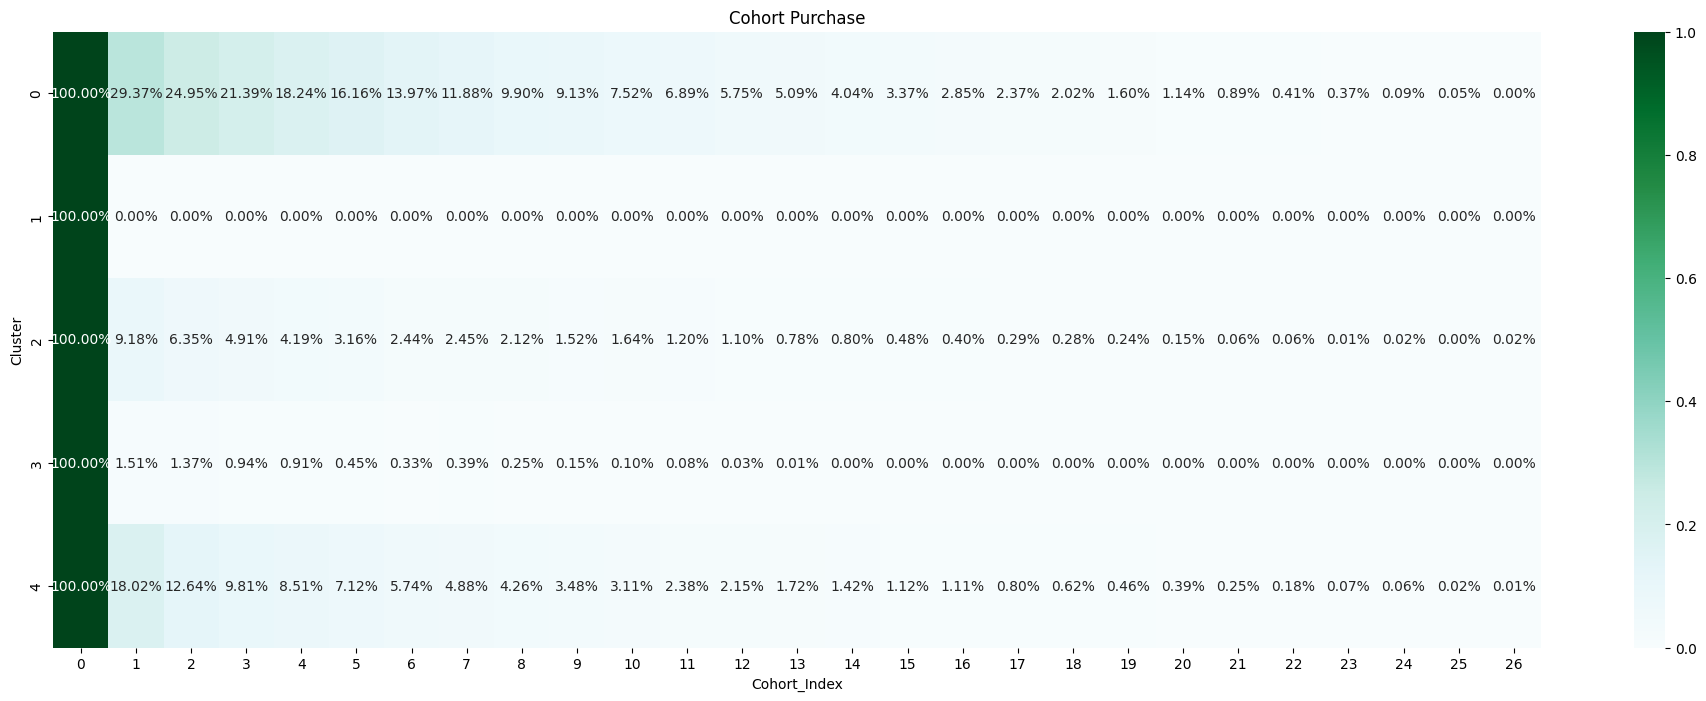

In [ ]:
cohort_data = orders1.groupby(['Cluster', 'Cohort_Index'])['user_id'].nunique().reset_index()

cohort_pivot = cohort_data.pivot(index='Cluster', columns='Cohort_Index', values='user_id')
cohort_size = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_size, axis=0)
retention.fillna(0, inplace =True)
plt.figure(figsize=(24, 8))
sns.heatmap(retention, annot=True, fmt='.2%', cmap='BuGn')
plt.title("Cohort Purchase")

In [ ]:
first_event = events.sort_values(by='created_at').drop_duplicates(subset='user_id', keep='first')
first_event['Cohort_Month'] = first_event['created_at'].dt.to_period('Q')
events1 = events.copy()
events1['Order_Month'] = events1['created_at'].dt.to_period('Q')

events1 = events1.merge(first_event[['user_id', 'Cohort_Month']], on='user_id', how='left')
events1['Cohort_Index'] = (events1['Order_Month'] - events1['Cohort_Month']).apply(lambda x: x.n)
events1 = events1.merge(purchasing_users_scaled[['user_id', 'Cluster']], on='user_id', how='left')
events1

/tmp/ipykernel_3379/2118031085.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  first_event['Cohort_Month'] = first_event['created_at'].dt.to_period('Q')
/tmp/ipykernel_3379/2118031085.py:4: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  events1['Order_Month'] = events1['created_at'].dt.to_period('Q')


,id,user_id,sequence_number,session_id,created_at,ip_address,city,state,postal_code,browser,traffic_source,uri,event_type,Order_Month,Cohort_Month,Cohort_Index,Cluster
0,2104558,NaN,3,08ec57db-2678-4185-a2fe-04d704253c1c,2025-07-26 18:13:00+00:00,201.227.177.158,Loda City,Akita,018-5201,Chrome,Adwords,/cancel,cancel,2025Q3,2019Q1,26,NaN
1,2221528,NaN,3,8c4b23dc-e44e-4f9a-8b94-cc9e039b1112,2019-01-14 07:51:00+00:00,173.93.91.78,São Paulo,São Paulo,02675-031,Safari,YouTube,/cancel,cancel,2019Q1,2019Q1,0,NaN
2,2289147,NaN,3,83c64c1d-2357-4527-af5c-42576db30a59,2022-12-10 06:23:00+00:00,30.40.14.164,São Paulo,São Paulo,02675-031,Chrome,Email,/cancel,cancel,2022Q4,2019Q1,15,NaN
3,1625584,NaN,3,5188d2e6-5cdf-4f0f-b18a-8ff884806725,2024-02-16 05:30:00+00:00,76.112.166.147,São Paulo,São Paulo,02675-031,IE,Email,/cancel,cancel,2024Q1,2019Q1,20,NaN
4,1563494,NaN,3,355db032-17b9-48a3-a9de-49ca235c6db1,2025-01-15 05:01:00+00:00,175.63.220.123,São Paulo,São Paulo,02675-031,Chrome,Facebook,/cancel,cancel,2025Q1,2019Q1,24,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2433502,674064,51646.0,7,87fcafd4-0179-4c1f-b8b1-bdd22b96a2bb,2019-07-15 09:47:36+00:00,155.123.49.113,Southall,England,UB1,Chrome,Adwords,/purchase,purchase,2019Q3,2019Q3,0,3.0
2433503,792695,60627.0,5,f5e02607-055c-41db-bded-fc76f81a93cb,2025-05-09 23:27:40+00:00,41.84.152.157,Warrington,England,WA4,Firefox,Facebook,/purchase,purchase,2025Q2,2021Q1,17,4.0
2433504,161559,12521.0,5,d41ca1f5-b670-4140-97d6-80a7505896a3,2021-10-11 00:34:50+00:00,58.46.218.112,Warrington,England,WA4,Chrome,Email,/purchase,purchase,2021Q4,2021Q4,0,3.0
2433505,327871,25239.0,5,9afa1aab-043d-4b97-a4c8-d2279f707334,2025-08-23 16:02:56+00:00,170.87.101.148,Wakefield,England,WF2,IE,Email,/purchase,purchase,2025Q3,2025Q3,0,1.0


Text(0.5, 1.0, 'Cohort Visit')

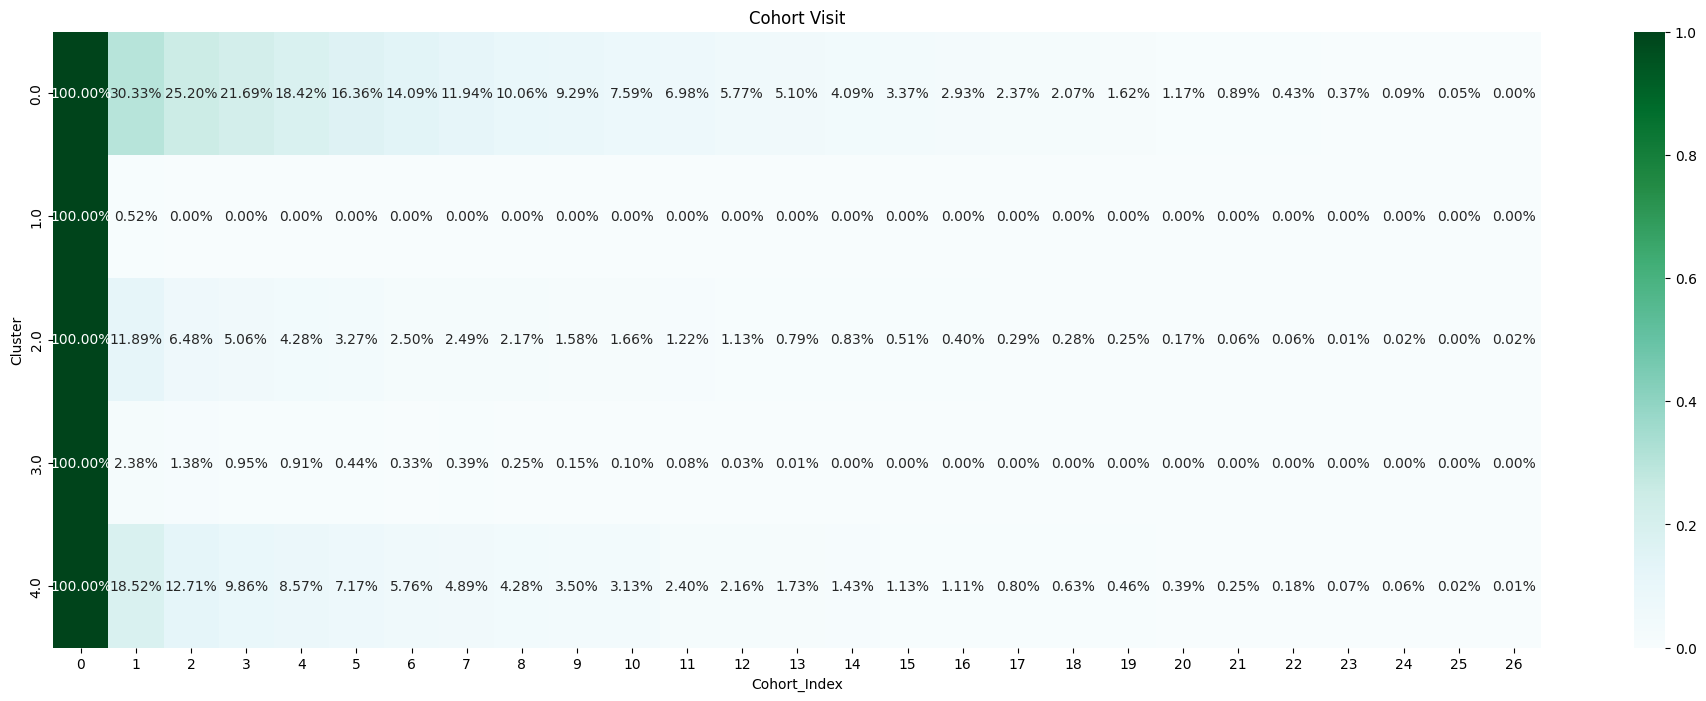

In [ ]:
cohort_visit = events1.groupby(['Cluster', 'Cohort_Index'])['user_id'].nunique().reset_index()

cohort_pivot_visit = cohort_visit.pivot(index='Cluster', columns='Cohort_Index', values='user_id')
cohort_size = cohort_pivot_visit.iloc[:, 0]
retention_visit = cohort_pivot_visit.divide(cohort_size, axis=0)
retention_visit.fillna(0, inplace =True)
plt.figure(figsize=(24, 8))
sns.heatmap(retention_visit, annot=True, fmt='.2%', cmap='BuGn')
plt.title("Cohort Visit")

#VDAR

In [ ]:
import numpy as np
import pandas as pd
import cudf
from cuml.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import matplotlib.pyplot as plt

# 1. TẠO DATASET VDAR+D+C CHO KHÁCH ẨN DANH
# Giả sử 'events' là dataframe gốc của bạn
anon_events = events[events['user_id'].isnull()].copy()

# Tính Duration cho mỗi Session
anon_events['created_at'] = pd.to_datetime(anon_events['created_at'])
sess_time = anon_events.groupby('session_id')['created_at'].agg(['min', 'max'])
sess_time['duration'] = (sess_time['max'] - sess_time['min']).dt.total_seconds()
product_view1 = events[events['event_type']=='product'].groupby('ip_address')['uri'].nunique().reset_index(name='Diversity_View')

# Group by ip_address để tính các chỉ số
vdar_dc = anon_events.groupby('ip_address').agg(
    Visits=('session_id', 'nunique'),
    Actions=('id', 'count'),
    Add_to_Cart_Count=('event_type', lambda x: (x == 'cart').sum())
).reset_index()

# Merge Duration vào
total_dur = anon_events.merge(sess_time[['duration']], left_on='session_id', right_index=True)
total_dur_ip = total_dur.groupby('ip_address')['duration'].sum().reset_index()
vdar_dc = vdar_dc.merge(total_dur_ip, on='ip_address')
vdar_dc = vdar_dc.merge(product_view1, on='ip_address', how='left')
vdar_dc.rename(columns={'duration': 'Durations'}, inplace=True)

features = ['Visits', 'Durations', 'Actions', 'Diversity_View', 'Add_to_Cart_Count']
vdar_dc

,ip_address,Visits,Actions,Add_to_Cart_Count,Durations,Diversity_View
0,1.0.129.166,1,3,1,8820.0,1
1,1.0.213.48,1,3,1,3780.0,1
2,1.0.25.136,1,3,1,1440.0,1
3,1.0.35.141,1,3,1,5940.0,1
4,1.0.7.76,1,3,1,1800.0,1
...,...,...,...,...,...,...
499965,99.99.189.103,1,3,1,3240.0,1
499966,99.99.190.30,1,1,0,0.0,1
499967,99.99.30.199,1,2,0,0.0,1
499968,99.99.73.101,1,1,0,0.0,1


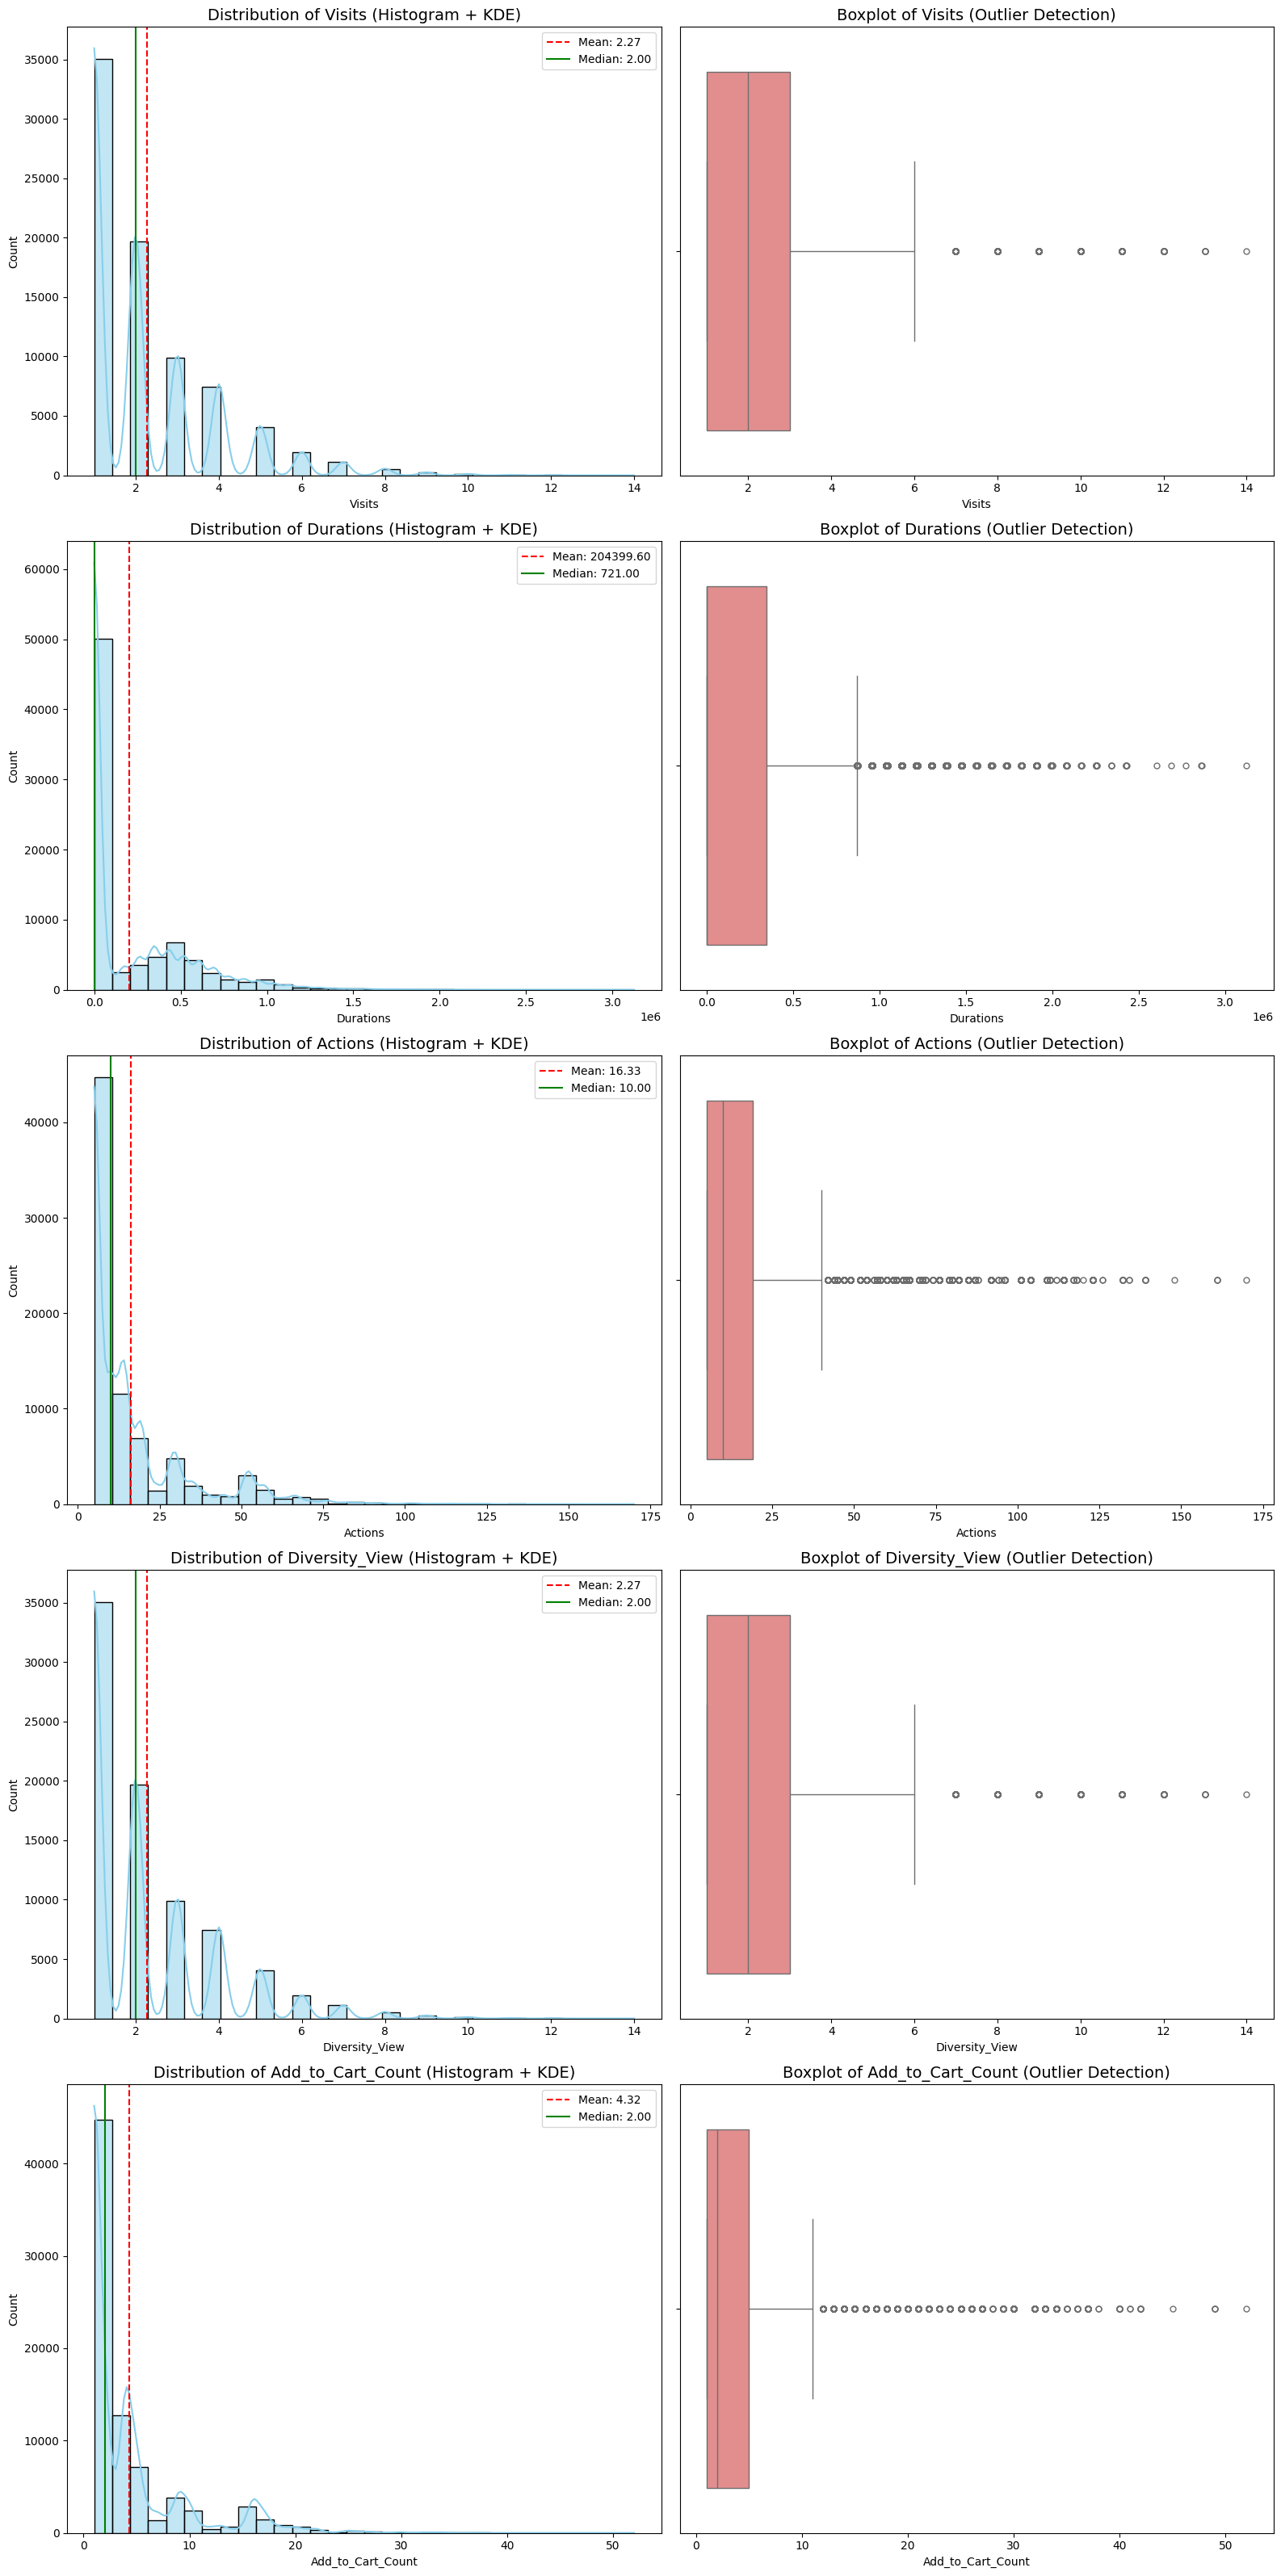

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Định nghĩa danh sách các đặc trưng RFMVDA++


# 2. Cấu hình vùng vẽ biểu đồ (mỗi đặc trưng gồm 1 Hist và 1 Boxplot song song)
# Theo đúng phương pháp "Histogram + boxplot song song" [cite: 65]
fig, axes = plt.subplots(nrows=len(features), ncols=2, figsize=(16, 4 * len(rfmvda_cols)))

for i, col in enumerate(features):
    # --- Vẽ Histogram + KDE ---
    # Overlay mean và median để kiểm tra độ lệch (skewness) [cite: 75, 76]
    sns.histplot(purchasing_users[col], kde=True, ax=axes[i, 0], color='skyblue', bins=30)

    mean_val = purchasing_users[col].mean()
    median_val = purchasing_users[col].median()

    axes[i, 0].axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:.2f}')
    axes[i, 0].axvline(median_val, color='green', linestyle='-', label=f'Median: {median_val:.2f}')

    axes[i, 0].set_title(f'Distribution of {col} (Histogram + KDE)', fontsize=14)
    axes[i, 0].legend()

    # --- Vẽ Boxplot ---
    # Giúp phát hiện hiện tượng "đuôi dài" và outliers [cite: 63, 67, 72]
    sns.boxplot(x=purchasing_users[col], ax=axes[i, 1], color='lightcoral', fliersize=5)
    axes[i, 1].set_title(f'Boxplot of {col} (Outlier Detection)', fontsize=14)

# 3. Xử lý Log-scale cho các biến bị lệch phải nặng (như Monetary, Actions)
# Đây là kỹ thuật quan trọng để làm rõ phân phối của dữ liệu lệch
# Ví dụ: axes[2, 0].set_xscale('log') # Nếu Monetary quá lệch

plt.tight_layout()
plt.savefig('rfmvda_distribution_analysis1.png')
plt.show()

In [ ]:
vdar_scaled = vdar_dc.copy()

# Log transform để xử lý đuôi dài (Outliers)
for col in features:
    vdar_scaled[col] = np.log1p(vdar_scaled[col])

# Scale về 0-5 theo quy chuẩn bài báo
scaler = MinMaxScaler(feature_range=(0, 5))
vdar_scaled[features] = scaler.fit_transform(vdar_scaled[features])

🚀 Đang phân tích trên 499970 dòng (Silhouette tính trên mẫu 20000 dòng)...
✅ K=2 | Silhouette: 0.7347
✅ K=3 | Silhouette: 0.7176
✅ K=4 | Silhouette: 0.9147
✅ K=5 | Silhouette: 0.9147
✅ K=6 | Silhouette: 0.9147
✅ K=7 | Silhouette: 0.7823
✅ K=8 | Silhouette: 0.9147
✅ K=9 | Silhouette: 0.7785
✅ K=10 | Silhouette: 0.8636


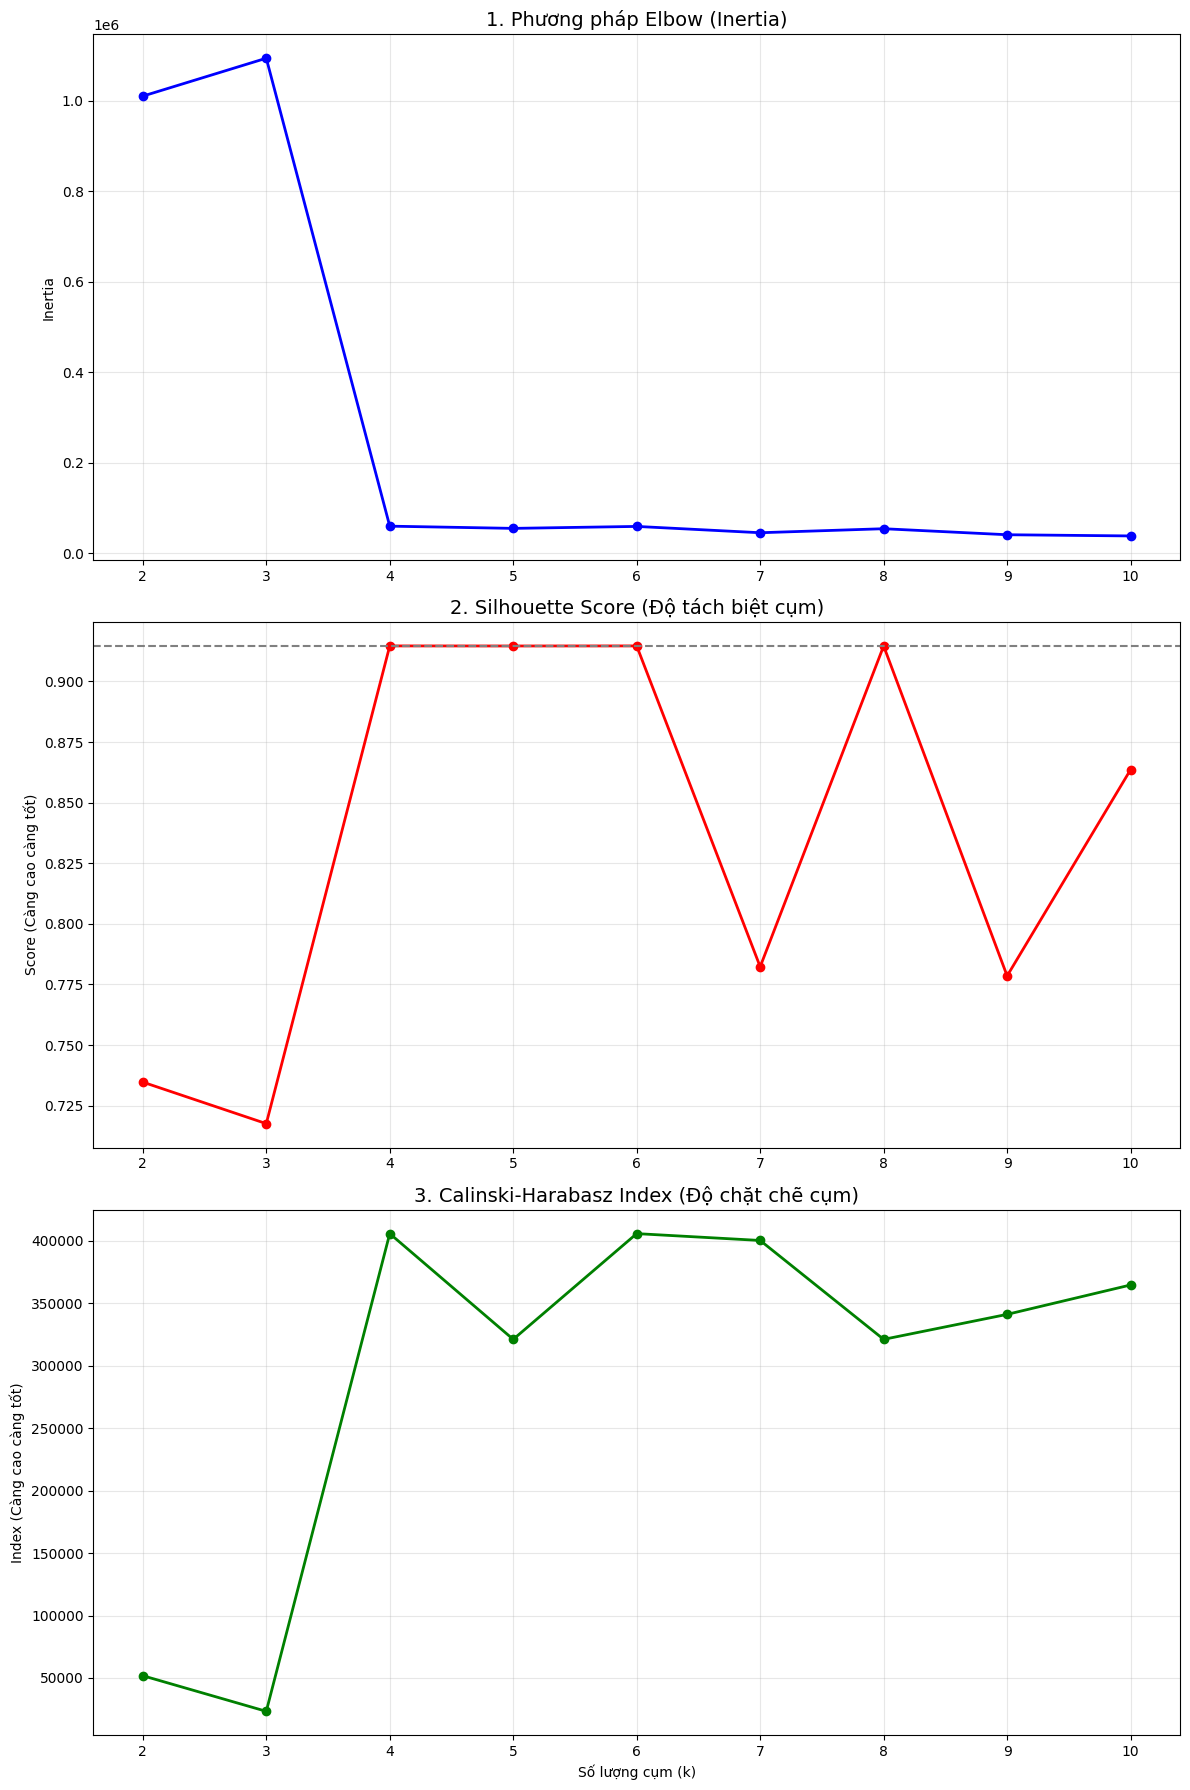

In [ ]:
evaluate_clusters_comprehensive(vdar_scaled, features)

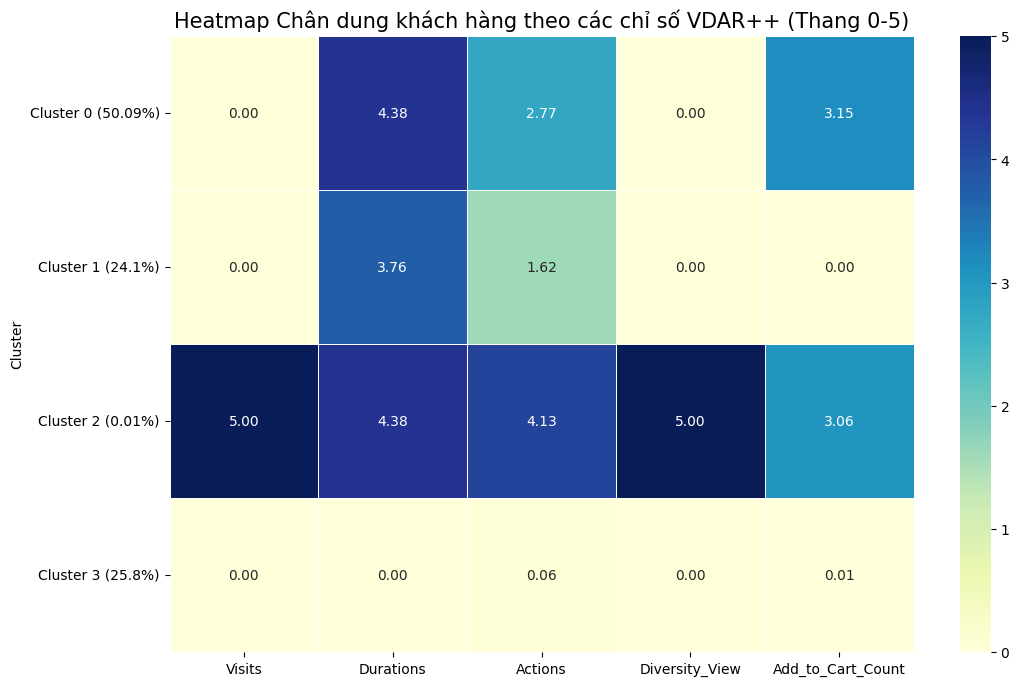

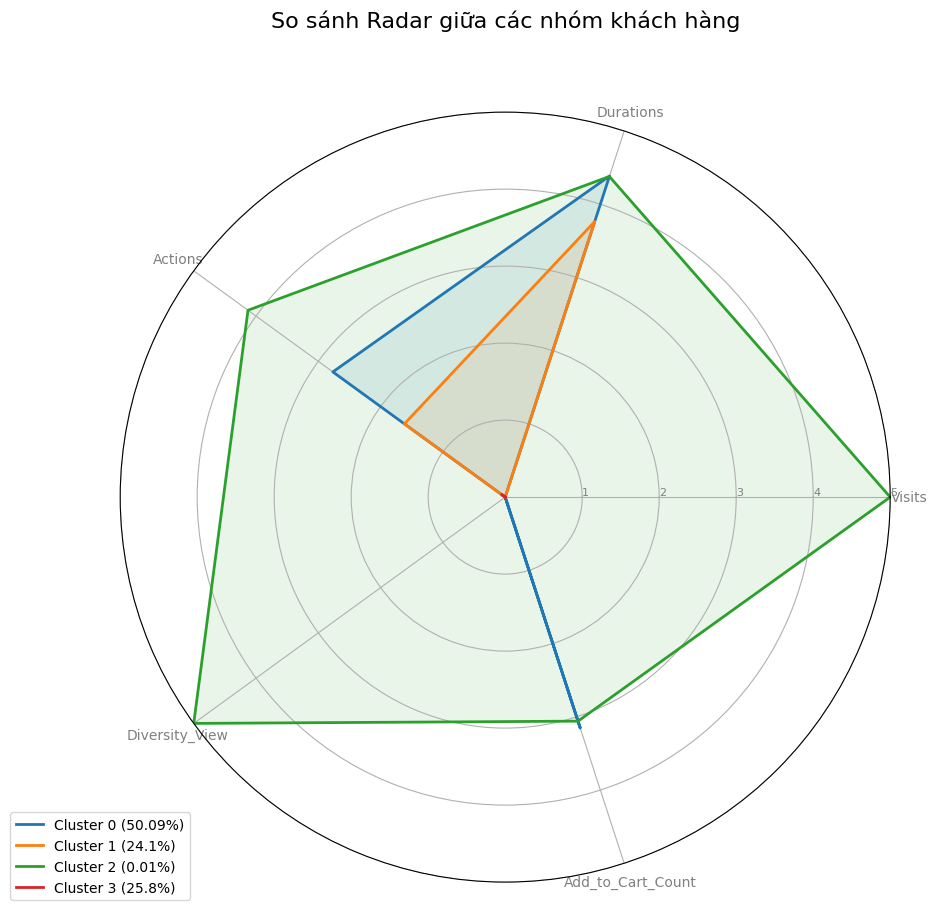

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# 1. Tính toán giá trị trung bình và % quy mô từng Cluster
# rfmvda_features = ['Recency', 'Frequency', 'Monetary', 'Visits', 'Durations', 'Actions', 'Diversity', 'Add_to_Cart_Count']
# 1. Chuyển dữ liệu sang GPU
gdf = cudf.from_pandas(vdar_scaled[features])

# 2. Huấn luyện KMeans với k=5 (Dựa trên đỉnh CH Index và khuỷu tay Elbow)
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(gdf)

# 3. Lấy nhãn dự đoán và đưa về CPU (NumPy) để tính toán metrics
labels_all = kmeans.labels_.to_numpy()
vdar_scaled['Cluster'] = labels_all
# Tính toán các chỉ số trung bình
cluster_profile = vdar_scaled.groupby('Cluster')[features].mean()

# Tính số lượng và % của từng nhóm
cluster_counts = vdar_scaled['Cluster'].value_counts().sort_index()
cluster_pcts = (cluster_counts / len(vdar_scaled) * 100).round(2)

# Tạo nhãn cho Cluster kèm % (ví dụ: Cluster 0 (15.2%))
cluster_labels = [f"Cluster {i} ({pct}%)" for i, pct in enumerate(cluster_pcts)]

# --- BIỂU ĐỒ 1: HEATMAP PROFILE ---
plt.figure(figsize=(12, 8))
sns.heatmap(cluster_profile, annot=True, cmap='YlGnBu', fmt=".2f", linewidths=.5)
plt.yticks(ticks=np.arange(len(cluster_labels)) + 0.5, labels=cluster_labels, rotation=0)
plt.title('Heatmap Chân dung khách hàng theo các chỉ số VDAR++ (Thang 0-5)', fontsize=15)
plt.savefig('cluster_heatmap_profile.png')
plt.show()

# --- BIỂU ĐỒ 2: RADAR CHART (SPIDER CHART) ---
def plot_radar_chart(df, labels):
    categories = list(df.columns)
    N = len(categories)

    # Tính toán góc cho mỗi trục
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

    # Màu sắc cho 5 cụm
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

    for i in range(len(df)):
        values = df.iloc[i].values.flatten().tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=labels[i], color=colors[i])
        ax.fill(angles, values, colors[i], alpha=0.1)

    # Thêm nhãn cho các trục
    plt.xticks(angles[:-1], categories, color='grey', size=10)

    # Thiết lập giới hạn trục (Thang 0-5 theo nghiên cứu)
    ax.set_rlabel_position(0)
    plt.yticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5"], color="grey", size=8)
    plt.ylim(0, 5)

    plt.title('So sánh Radar giữa các nhóm khách hàng', size=16, y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
    plt.savefig('cluster_radar_chart.png')
    plt.show()

plot_radar_chart(cluster_profile, cluster_labels)

In [ ]:
# 1. Gán nhãn Cluster từ bảng đã scale quay trở lại bảng dữ liệu gốc (vdar_dc)
vdar_dc['Cluster'] = vdar_scaled['Cluster'].values

# 2. Tính giá trị trung bình thực tế (Actual Mean) cho từng cụm
# features = ['Visits', 'Durations', 'Actions', 'Diversity_View', 'Add_to_Cart_Count']
actual_profile = vdar_dc.groupby('Cluster')[features].mean()

# 3. Tính thêm số lượng IP và tỷ lệ % quy mô của từng nhóm
cluster_counts = vdar_dc['Cluster'].value_counts().sort_index()
actual_profile['User_Count'] = cluster_counts.values
actual_profile['Size (%)'] = (cluster_counts.values / len(vdar_dc) * 100).round(2)

# 4. Sắp xếp lại để dễ nhìn và in kết quả
print("--- BẢNG PHÂN TÍCH GIÁ TRỊ THỰC TẾ (ACTUAL VALUES) ---")
display(actual_profile.style.format("{:.2f}").background_gradient(cmap='Blues'))

--- BẢNG PHÂN TÍCH GIÁ TRỊ THỰC TẾ (ACTUAL VALUES) ---


,Visits,Durations,Actions,Diversity_View,Add_to_Cart_Count,User_Count,Size (%)
Cluster,,,,,,,
0,1.00,5229.92,3.00,1.00,1.00,250429.00,50.09
1,1.00,1795.86,2.00,1.00,0.00,120513.00,24.10
2,2.00,6750.00,4.73,2.00,1.07,30.00,0.01
3,1.00,0.00,1.04,1.00,0.00,128998.00,25.80


In [ ]:
first_event_ip = events.sort_values(by='created_at').drop_duplicates(subset='ip_address', keep='first')
first_event_ip['Cohort_Month'] = first_event_ip['created_at'].dt.to_period('Q')

events1 = events.copy()
events1['Order_Month'] = events1['created_at'].dt.to_period('Q')

events1 = events1.merge(first_event_ip[['ip_address', 'Cohort_Month']], on='ip_address', how='left')
events1['Cohort_Index'] = (events1['Order_Month'] - events1['Cohort_Month']).apply(lambda x: x.n)
events1 = events1.merge(vdar_dc[['ip_address', 'Cluster']], on='ip_address', how='left')
events1

cohort_visit = events1.groupby(['Cluster', 'Cohort_Index'])['ip_address'].nunique().reset_index()

cohort_pivot_visit = cohort_visit.pivot(index='Cluster', columns='Cohort_Index', values='ip_address')
cohort_size = cohort_pivot_visit.iloc[:, 0]
retention_visit = cohort_pivot_visit.divide(cohort_size, axis=0)
retention_visit.fillna(0, inplace =True)
plt.figure(figsize=(24, 8))


/tmp/ipykernel_3379/827520765.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  first_event_ip['Cohort_Month'] = first_event_ip['created_at'].dt.to_period('Q')
/tmp/ipykernel_3379/827520765.py:5: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  events1['Order_Month'] = events1['created_at'].dt.to_period('Q')


<Figure size 2400x800 with 0 Axes>

<Figure size 2400x800 with 0 Axes>